# MTPFN on our A→B prior (with the transform class): standalone report and diagnosis

## Description

*Written 2026-11-03, before the diagnostics ran. Issue #20, branch `exp/20-mtpfn`. Arm A of notebook 12, as a standalone report. Arm R (the paper's own ICM prior) stays in notebook 12 and runs later.*

**Idea.** MTPFN (Li, Daulton, Müller, Wilson, Bakshy; SPIGM @ NeurIPS 2025) is the published PFN for in-context transfer between tasks.
- **Data.** Every task's points form a set. Each task also gets a [TASK] summary token.
- **Within a task** (intra-task attention): points and the [TASK] token attend to each other. The target's query points read only the target's own tokens.
- **Between tasks** (inter-task attention): only the [TASK] tokens attend to each other, so all transfer passes through one vector per task and layer.
- **Training.** The paper trains it on a robust ICM prior, where tasks share a lengthscale and correlate; with probability p a source task is unrelated.

**What we ask here.** Train the same architecture on *our* prior, the pilot-3 AIR prior:
- B: a dense source (128 points, noise σ_B);
- A: a scarce target (n_A ∈ 1..10);
- f_A(x) = g(T_θ(x)), with g a random MLP on the global ECDF scale;
- T_θ a monotone, box-preserving flow from the transform class, J ∈ {2, 4, 8, 16} coefficients;
- H0 (h = id) and Z0 (always related).

Then ask:
1. **Transfer.** How much better than A alone is it?
2. **Gap.** How far is it from the exact dense-B Bayes predictive (G-ref, J = 2), and from AIR (pilot 3, when its evaluation is in)?
3. **Diagnosis.** Why does it lose what it loses? Concretely: does it register B to A, that is, read B at T_θ(x*)?

**Setup.**
- **Model.** Width 128, N = 4 [intra, inter] pairs plus a final intra block, 4 heads, d_ff 512. That is 1.84M parameters, the AIR decoder + proposal budget, far below the paper's 23 × 512.
- **Training.** Bar output with AIR's bins (400 bins on [−0.25, 1.25]), so NLLs are on the same scale as AIR's. AdamW 1e-4, cosine, 100k steps × 64 tasks, seeds 0, 1, 2 (sweep `runs/mtpfn/pilot_20261103-132611`).
- **Evaluation.** Pilot 3's evaluation tasks: `eval_tasks(J, 256, seed 777, ecdf)`, J ∈ {2, 16}, n_A ∈ {1, 2, 3, 5, 10}, nested A designs.
- **References** on the same tasks:
  - pilot 3's clean A-only PFN, same seed (`aonly_pfn`);
  - G-ref at J = 2 (`gref`): exact Bayes given g, so a floor rather than a target.

**Diagnostics** (`experimental/mtpfn/diagnose.py`, mode `air_diag`, one run per seed):
- **D1 Transfer.** NLL(`aonly_pfn`) − NLL(MTPFN) per (J, n_A).
- **D2 Gap.** NLL(MTPFN) − NLL(`gref`), J = 2.
- **D3 Input controls** on the same tasks:
  - `b_registered`: B pulled into A's frame with the true θ. The gain over `b` is what MTPFN loses by having to handle the warp itself.
  - `b_other`: an unrelated B, i.e. another task's B.
  - `b_none`: B with only its [TASK] token, which is ≈ A-only and off-distribution.
- **D4 Where does it read B?**
  - Compute the sensitivity s_k = |∂E[y*|x*]/∂y_{B,k}| for every B point.
  - Summarise it as `read`, the sensitivity-weighted mean x_B, and `conc`, the share of sensitivity within ±0.05 of T_θ(x*).
  - Compare |read − T_θ(x*)| with |x* − T_θ(x*)|, i.e. with reading at x* itself.
- **D5 Calibration.** PIT of y* (128 tasks × 32 queries per cell).
- **D6 Warp size.** The D1 gain against the task's mean |T_θ(x) − x|.
- **Examples.** PPDs (mean and 5–95 % quantiles) on an x grid next to f_A, B, A and the G-ref predictive.

**Reading rules (pre-registered).** n_A ≥ 3, averaged over tasks; means over 3 seeds ± SE where that applies:
- **"MTPFN registers"**: median `conc` ≥ 0.5 and median |read − T| < median |x* − T|.
- **"It reads globally (summary transfer)"**: median `conc` < 0.2 and `read` ≈ 0.5 (|read − 0.5| < 0.1 for most x*).
- **"The warp is its bottleneck"**: NLL(`b`) − NLL(`b_registered`) ≥ 0.1 at n_A ≥ 2.
- **"Uses B"**: NLL(`b_other`) − NLL(`b`) ≥ 0.1.
- **Calibration**: reported as the PIT histogram plus the KS distance to uniform, no threshold.

**Expectation, written before the run.** MTPFN can pass B to A only through [TASK] summaries. So we expect it to use B (global level, scale, shape statistics), with a real gain over A-only at small n_A. But we expect it not to register B pointwise: low `conc`, a large `b_registered` gain, and a large gap to G-ref and to AIR, growing with J.

**Limits.** d = 1, Z0, H0 (pilot 3's scope). The model is smaller than the paper's. G-ref knows g exactly. Sensitivity is local (gradient), so it shows where the predictive *mean* reads, not the whole PPD.

## Results

Data: one `air_diag` run per seed on pilot 3's evaluation tasks; tables `ctrl`, `task_info`, `pit`, `sens`, `sensmap`, `ex`, `ex_pts` (experimental/mtpfn/diagnose.py).

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import kstest

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").is_dir() and (p / "src").is_dir()), Path.cwd())
DIAG = "pilot_20261103-160920".split(",")  # one air_diag sweep per seed (results/mtpfn/<id>), in seed order
TRAIN = "pilot_20261103-132611"  # the air_train sweep (members = seeds)


def _dir(s):
    p = Path(s)
    return p if p.is_absolute() else ROOT / "results/mtpfn" / s / "tables"


def load(name):
    return pd.concat([pd.read_parquet(_dir(s) / f"{name}.parquet").assign(seed=k) for k, s in enumerate(DIAG)])


ctrl, info, pit, sens, smap, ex, pts = (load(k) for k in ("ctrl", "task_info", "pit", "sens", "sensmap", "ex",
                                                          "ex_pts"))  # fmt: skip
NS, SEEDS = sorted(ctrl.n_a.unique()), sorted(ctrl.seed.unique())
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # fixed categorical order
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "lines.linewidth": 2,
                     "lines.markersize": 6, "text.color": INK, "axes.labelcolor": MUTED, "font.size": 10,
                     "legend.frameon": False})  # fmt: skip
LAB = {"aonly_pfn": "A-only PFN (pilot 3, clean)", "b": "MTPFN (B as given)", "b_registered": "MTPFN, B pre-registered",
       "b_other": "MTPFN, unrelated B", "b_none": "MTPFN, B removed", "gref": "G-ref (exact, dense B)"}


def seed_mean(df, by):
    """Per-seed task means, then the mean over seeds ± SE over seeds (one seed: SE over tasks)."""
    if len(SEEDS) > 1:
        m = df.groupby(by + ["seed"]).nll.mean().groupby(by)
        return pd.DataFrame({"mean": m.mean(), "se": m.std(ddof=1) / np.sqrt(len(SEEDS))})
    g = df.groupby(by).nll
    return pd.DataFrame({"mean": g.mean(), "se": g.std(ddof=1) / np.sqrt(g.count())})


print("seeds:", SEEDS, "| tasks per (J, n_A):", ctrl.groupby(["seed", "J", "n_a", "input"]).size().max())

seeds: [np.int64(0)] | tasks per (J, n_A): 128


### Training

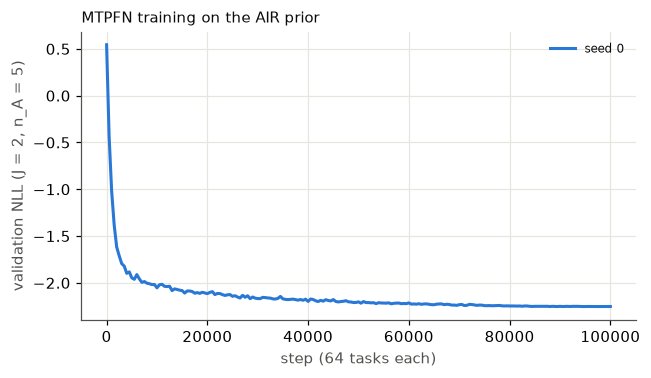

,member,step,val_nll,s
200,0,100000,-2.253,7955.559


In [ ]:
if TRAIN:
    tr = pd.read_parquet(ROOT / "results/mtpfn" / TRAIN / "tables" / "train.parquet")
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    for k, (m, d) in enumerate(tr.groupby("member")):
        ax.plot(d.step, d.val_nll, color=C[k], label=f"seed {m}")
    ax.set(xlabel="step (64 tasks each)", ylabel="validation NLL (J = 2, n_A = 5)")
    ax.set_title("MTPFN training on the AIR prior", loc="left", fontsize=10)
    ax.legend(fontsize=8)
    plt.show()
    display(tr.groupby("member").tail(1)[["member", "step", "val_nll", "s"]].round(3))

### D1–D3: transfer, gap to the exact reference, input controls

In [ ]:
piv = {}
for J in sorted(ctrl.J.unique()):
    t = seed_mean(ctrl[ctrl.J == J], ["n_a", "input"])
    piv[J] = t["mean"].unstack("input").round(3)
    print(f"J = {J}: mean NLL per query (lower is better); seeds {SEEDS}")
    display(piv[J][[c for c in LAB if c in piv[J]]].rename(columns=LAB))


def paired(J, a, b):
    """mean over tasks of NLL(a) - NLL(b), paired by (seed, task); mean ± SE as in seed_mean."""
    w = ctrl[ctrl.J == J].pivot_table(index=["seed", "n_a", "task"], columns="input", values="nll")
    d = (w[a] - w[b]).rename("nll").reset_index()
    return seed_mean(d, ["n_a"])


rows = []
for J in sorted(ctrl.J.unique()):
    for name, a, b in [("D1 transfer: A-only − MTPFN", "aonly_pfn", "b"),
                       ("D3 warp cost: MTPFN − MTPFN(B registered)", "b", "b_registered"),
                       ("D3 uses B: MTPFN(unrelated B) − MTPFN", "b_other", "b"),
                       ("D2 gap: MTPFN − G-ref", "b", "gref"),
                       ("registered gap: MTPFN(B registered) − G-ref", "b_registered", "gref")]:
        if a in ctrl.input.unique() and b in ctrl[ctrl.J == J].input.unique():
            p = paired(J, a, b)
            rows += [{"J": J, "quantity": name, "n_a": n, "value": f"{r['mean']:+.3f} ± {r['se']:.3f}"}
                     for n, r in p.iterrows()]
display(pd.DataFrame(rows).pivot_table(index=["J", "quantity"], columns="n_a", values="value", aggfunc="first"))

J = 2: mean NLL per query (lower is better); seeds [np.int64(0)]


input,"A-only PFN (pilot 3, clean)",MTPFN (B as given),"MTPFN, B pre-registered","MTPFN, unrelated B","MTPFN, B removed","G-ref (exact, dense B)"
n_a,,,,,,
1,-0.789,-1.906,-2.029,3.257,1.106,-2.139
2,-1.288,-2.035,-2.118,2.052,0.112,-2.322
3,-1.557,-2.107,-2.173,1.291,-0.354,-2.399
5,-1.877,-2.235,-2.268,0.434,-1.083,-2.516
10,-2.193,-2.423,-2.414,-0.542,-1.915,-2.687


J = 16: mean NLL per query (lower is better); seeds [np.int64(0)]


input,"A-only PFN (pilot 3, clean)",MTPFN (B as given),"MTPFN, B pre-registered","MTPFN, unrelated B","MTPFN, B removed"
n_a,,,,,
1,-0.912,-1.904,-2.018,3.301,1.103
2,-1.327,-2.028,-2.098,2.218,0.202
3,-1.599,-2.109,-2.152,1.534,-0.435
5,-1.890,-2.193,-2.222,0.657,-1.244
10,-2.156,-2.307,-2.318,-0.420,-1.875


n_a                                                         1   \
J  quantity                                                      
2  D1 transfer: A-only − MTPFN                  +1.117 ± 0.070   
   D2 gap: MTPFN − G-ref                        +0.233 ± 0.025   
   D3 uses B: MTPFN(unrelated B) − MTPFN        +5.163 ± 0.226   
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.123 ± 0.020   
   registered gap: MTPFN(B registered) − G-ref  +0.110 ± 0.027   
16 D1 transfer: A-only − MTPFN                  +0.992 ± 0.057   
   D3 uses B: MTPFN(unrelated B) − MTPFN        +5.205 ± 0.223   
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.114 ± 0.019   

n_a                                                         2   \
J  quantity                                                      
2  D1 transfer: A-only − MTPFN                  +0.747 ± 0.049   
   D2 gap: MTPFN − G-ref                        +0.287 ± 0.028   
   D3 uses B: MTPFN(unrelated B) − MTPFN        +4.087 ± 0.193   
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.083 ± 0.017   
   registered gap: MTPFN(B registered) − G-ref  +0.204 ± 0.028   
16 D1 transfer: A-only − MTPFN                  +0.702 ± 0.043   
   D3 uses B: MTPFN(unrelated B) − MTPFN        +4.246 ± 0.182   
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.069 ± 0.013   

n_a                                                         3   \
J  quantity                                                      
2  D1 transfer: A-only − MTPFN                  +0.551 ± 0.041   
   D2 gap: MTPFN − G-ref                        +0.291 ± 0.025   
   D3 uses B: MTPFN(unrelated B) − MTPFN        +3.399 ± 0.167   
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.066 ± 0.016   
   registered gap: MTPFN(B registered) − G-ref  +0.226 ± 0.027   
16 D1 transfer: A-only − MTPFN                  +0.510 ± 0.036   
   D3 uses B: MTPFN(unrelated B) − MTPFN        +3.643 ± 0.162   
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.043 ± 0.011   

n_a                                                         5               10  
J  quantity                                                                     
2  D1 transfer: A-only − MTPFN                  +0.358 ± 0.036  +0.230 ± 0.028  
   D2 gap: MTPFN − G-ref                        +0.281 ± 0.025  +0.264 ± 0.023  
   D3 uses B: MTPFN(unrelated B) − MTPFN        +2.669 ± 0.129  +1.881 ± 0.090  
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.033 ± 0.014  -0.009 ± 0.011  
   registered gap: MTPFN(B registered) − G-ref  +0.248 ± 0.028  +0.273 ± 0.025  
16 D1 transfer: A-only − MTPFN                  +0.304 ± 0.026  +0.151 ± 0.016  
   D3 uses B: MTPFN(unrelated B) − MTPFN        +2.850 ± 0.140  +1.887 ± 0.100  
   D3 warp cost: MTPFN − MTPFN(B registered)    +0.029 ± 0.010  +0.011 ± 0.008

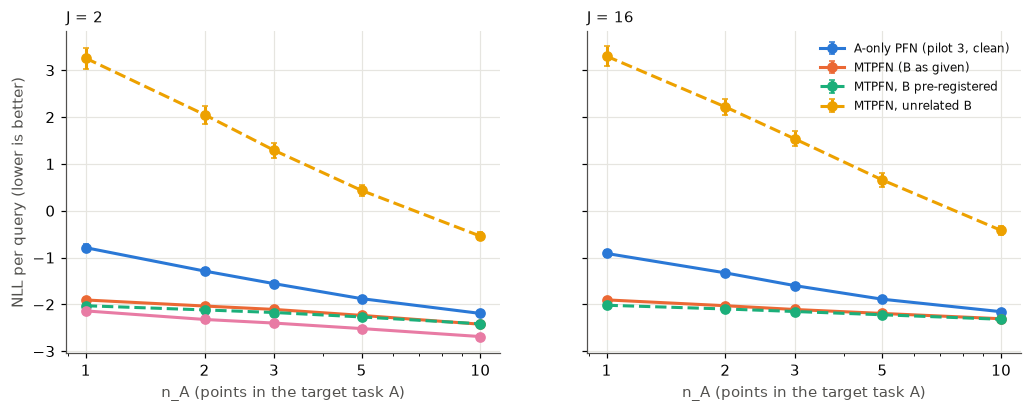

In [ ]:
Js = sorted(ctrl.J.unique())
fig, axs = plt.subplots(1, len(Js), figsize=(5.6 * len(Js), 3.8), sharey=True)
axs = np.atleast_1d(axs)
for ax, J in zip(axs, Js):
    t = seed_mean(ctrl[ctrl.J == J], ["input", "n_a"])
    for k, inp in enumerate(["aonly_pfn", "b", "b_registered", "b_other", "gref"]):
        if inp not in t.index.get_level_values(0):
            continue
        d = t.loc[inp]
        ls = "--" if inp in ("b_registered", "b_other") else "-"
        ax.errorbar(d.index, d["mean"], yerr=d["se"], color=C[k], ls=ls, marker="o", capsize=2, label=LAB[inp])
    ax.set(xscale="log", xticks=NS, xticklabels=NS, xlabel="n_A (points in the target task A)")
    ax.set_title(f"J = {J}", loc="left", fontsize=10)
axs[0].set_ylabel("NLL per query (lower is better)")
axs[-1].legend(fontsize=8, loc="upper right")
plt.show()

### D4: where does the MTPFN read B?

conc_median  read_err_median  identity_err_median  \
J  n_a                                                      
2  1          0.153            0.160                0.072   
   2          0.162            0.143                0.072   
   3          0.170            0.134                0.072   
   5          0.187            0.125                0.072   
   10         0.200            0.125                0.072   
16 1          0.168            0.163                0.092   
   2          0.167            0.156                0.092   
   3          0.175            0.144                0.092   
   5          0.186            0.140                0.092   
   10         0.193            0.129                0.092   

        share_read_near_middle  
J  n_a                          
2  1                     0.342  
   2                     0.336  
   3                     0.326  
   5                     0.318  
   10                    0.311  
16 1                     0.310  
   2                     0.359  
   3                     0.335  
   5                     0.342  
   10                    0.290

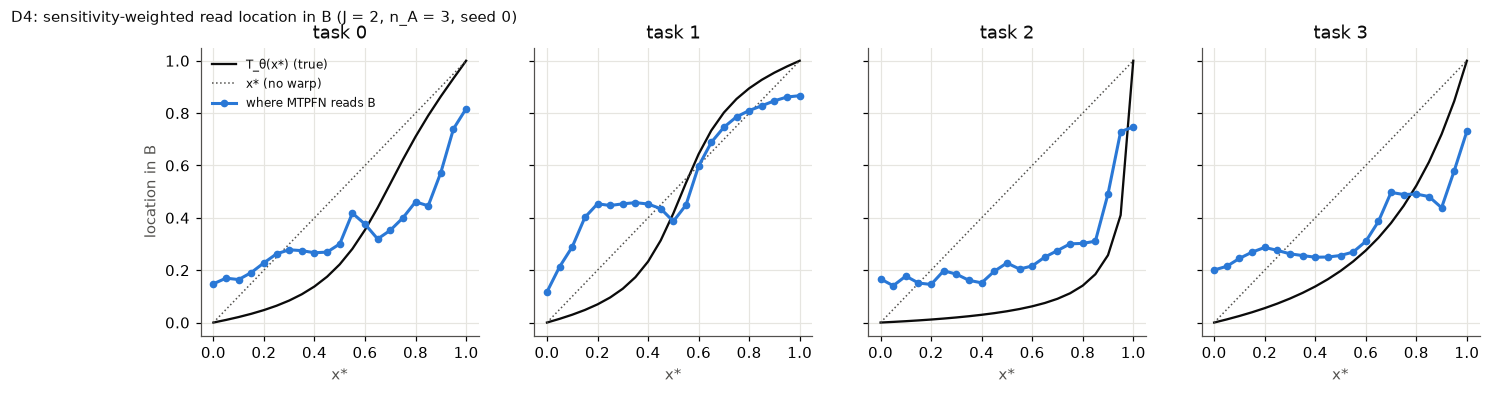

In [ ]:
s = sens.copy()
s["err_read"] = (s.read - s.true_t).abs()
s["err_id"] = (s.xq - s.true_t).abs()
s["read_mid"] = (s.read - 0.5).abs() < 0.1
tab4 = s.groupby(["J", "n_a"]).agg(conc_median=("conc", "median"), read_err_median=("err_read", "median"),
                                   identity_err_median=("err_id", "median"), share_read_near_middle=("read_mid", "mean"))
display(tab4.round(3))
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, (i, d) in zip(axs, s[(s.J == 2) & (s.n_a == 3) & (s.seed == 0)].groupby("task")):
    ax.plot(d.xq, d.true_t, color=INK, lw=1.5, label="T_θ(x*) (true)")
    ax.plot(d.xq, d.xq, color=MUTED, lw=1, ls=":", label="x* (no warp)")
    ax.plot(d.xq, d.read, color=C[0], marker="o", ms=4, label="where MTPFN reads B")
    ax.set(xlabel="x*", title=f"task {i}")
axs[0].set_ylabel("location in B")
axs[0].legend(fontsize=8)
plt.suptitle("D4: sensitivity-weighted read location in B (J = 2, n_A = 3, seed 0)", x=0.01, ha="left", fontsize=10)
plt.show()

/tmp/ipykernel_565626/1425653959.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  m = m.div(m.sum(1), axis=0)
/tmp/ipykernel_565626/1425653959.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  m = m.div(m.sum(1), axis=0)
/tmp/ipykernel_565626/1425653959.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  m = m.div(m.sum(1), axis=0)
/tmp/ipykernel_565626/1425653959.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  m = m.div(m.sum(1), axis=0)


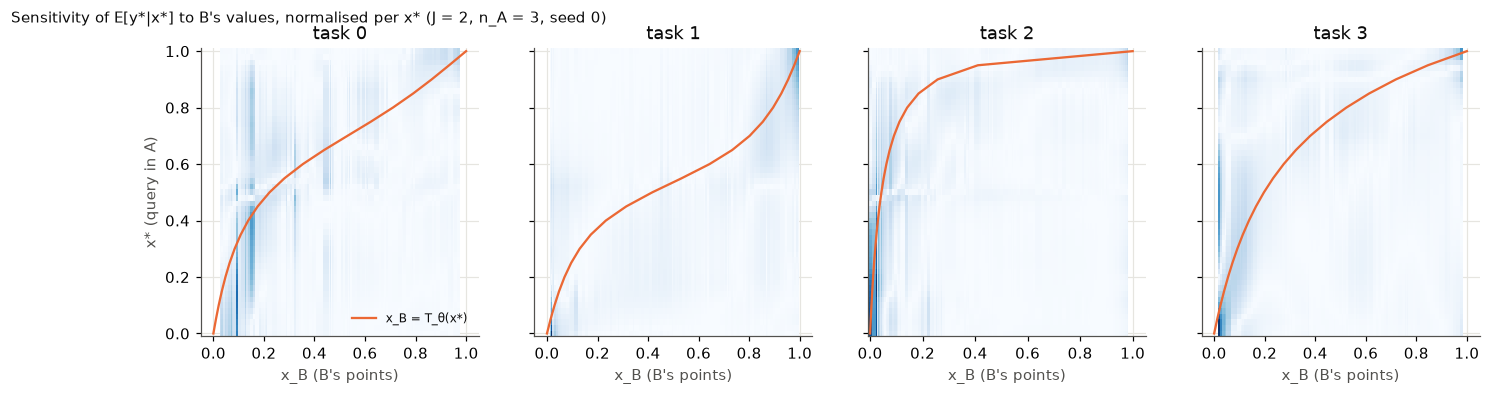

In [ ]:
sm = smap[(smap.J == 2) & (smap.n_a == 3) & (smap.seed == 0)]
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, (i, d) in zip(axs, sm.groupby("task")):
    m = d.pivot_table(index="xq", columns="xb", values="s")
    m = m.div(m.sum(1), axis=0)
    ax.pcolormesh(m.columns, m.index, m.values, cmap="Blues", shading="nearest")
    tt = s[(s.J == 2) & (s.n_a == 3) & (s.seed == 0) & (s.task == i)]
    ax.plot(tt.true_t, tt.xq, color=C[1], lw=1.5, label="x_B = T_θ(x*)")
    ax.set(xlabel="x_B (B's points)", title=f"task {i}")
axs[0].set_ylabel("x* (query in A)")
axs[0].legend(fontsize=8, loc="lower right")
plt.suptitle("Sensitivity of E[y*|x*] to B's values, normalised per x* (J = 2, n_A = 3, seed 0)", x=0.01, ha="left",
             fontsize=10)  # fmt: skip
plt.show()

### D5: calibration

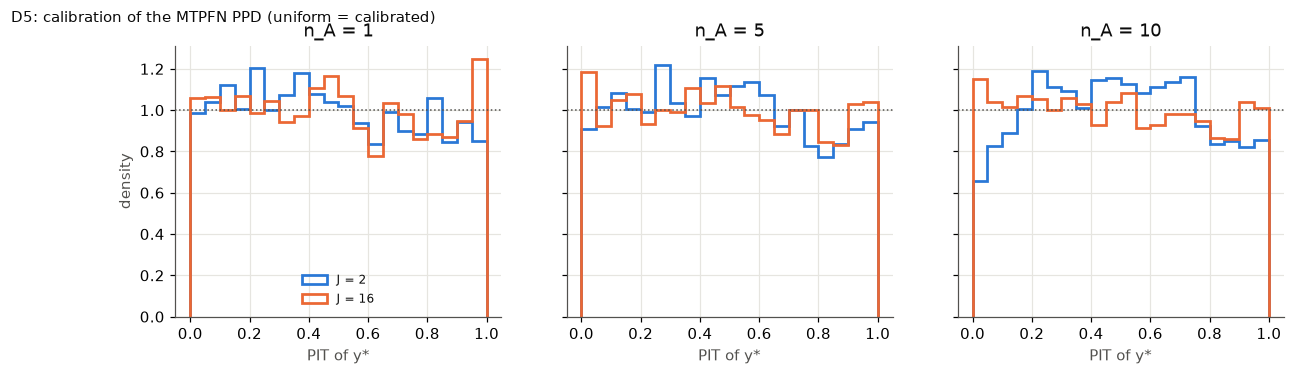

n_a,1,5,10
J,,,
2,0.040,0.041,0.038
16,0.027,0.025,0.025


In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
ksr = []
for ax, n in zip(axs, (1, 5, 10)):
    for k, J in enumerate(sorted(pit.J.unique())):
        v = pit[(pit.J == J) & (pit.n_a == n)].pit.values
        ax.hist(v, bins=20, range=(0, 1), density=True, histtype="step", color=C[k], lw=1.8, label=f"J = {J}")
        ksr.append({"J": J, "n_a": n, "ks_D": kstest(v, "uniform").statistic})
    ax.axhline(1, color=MUTED, lw=1, ls=":")
    ax.set(xlabel="PIT of y*", title=f"n_A = {n}")
axs[0].set_ylabel("density")
axs[0].legend(fontsize=8)
plt.suptitle("D5: calibration of the MTPFN PPD (uniform = calibrated)", x=0.01, ha="left", fontsize=10)
plt.show()
display(pd.DataFrame(ksr).pivot_table(index="J", columns="n_a", values="ks_D").round(3))

### D6: transfer and warp cost against the size of the warp

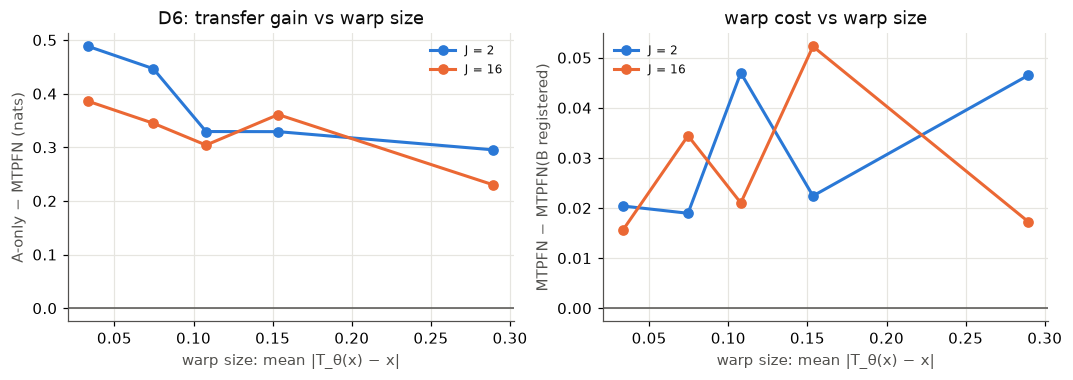

In [ ]:
w = ctrl.pivot_table(index=["seed", "J", "n_a", "task"], columns="input", values="nll").reset_index()
w = w.merge(info.drop_duplicates(["J", "task"])[["J", "task", "shift"]], on=["J", "task"])
w["shift_bin"] = pd.qcut(w["shift"], 5, duplicates="drop")
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.4))
for k, J in enumerate(sorted(w.J.unique())):
    d = w[(w.J == J) & (w.n_a >= 3)]
    if "aonly_pfn" in d:
        g = (d.aonly_pfn - d.b).groupby(d.shift_bin, observed=True).mean()
        axs[0].plot([iv.mid for iv in g.index], g.values, color=C[k], marker="o", label=f"J = {J}")
    g = (d.b - d.b_registered).groupby(d.shift_bin, observed=True).mean()
    axs[1].plot([iv.mid for iv in g.index], g.values, color=C[k], marker="o", label=f"J = {J}")
axs[0].set(xlabel="warp size: mean |T_θ(x) − x|", ylabel="A-only − MTPFN (nats)", title="D6: transfer gain vs warp size")
axs[1].set(xlabel="warp size: mean |T_θ(x) − x|", ylabel="MTPFN − MTPFN(B registered)", title="warp cost vs warp size")
for ax in axs:
    ax.axhline(0, color=MUTED, lw=1)
    ax.legend(fontsize=8)
plt.show()

### Examples

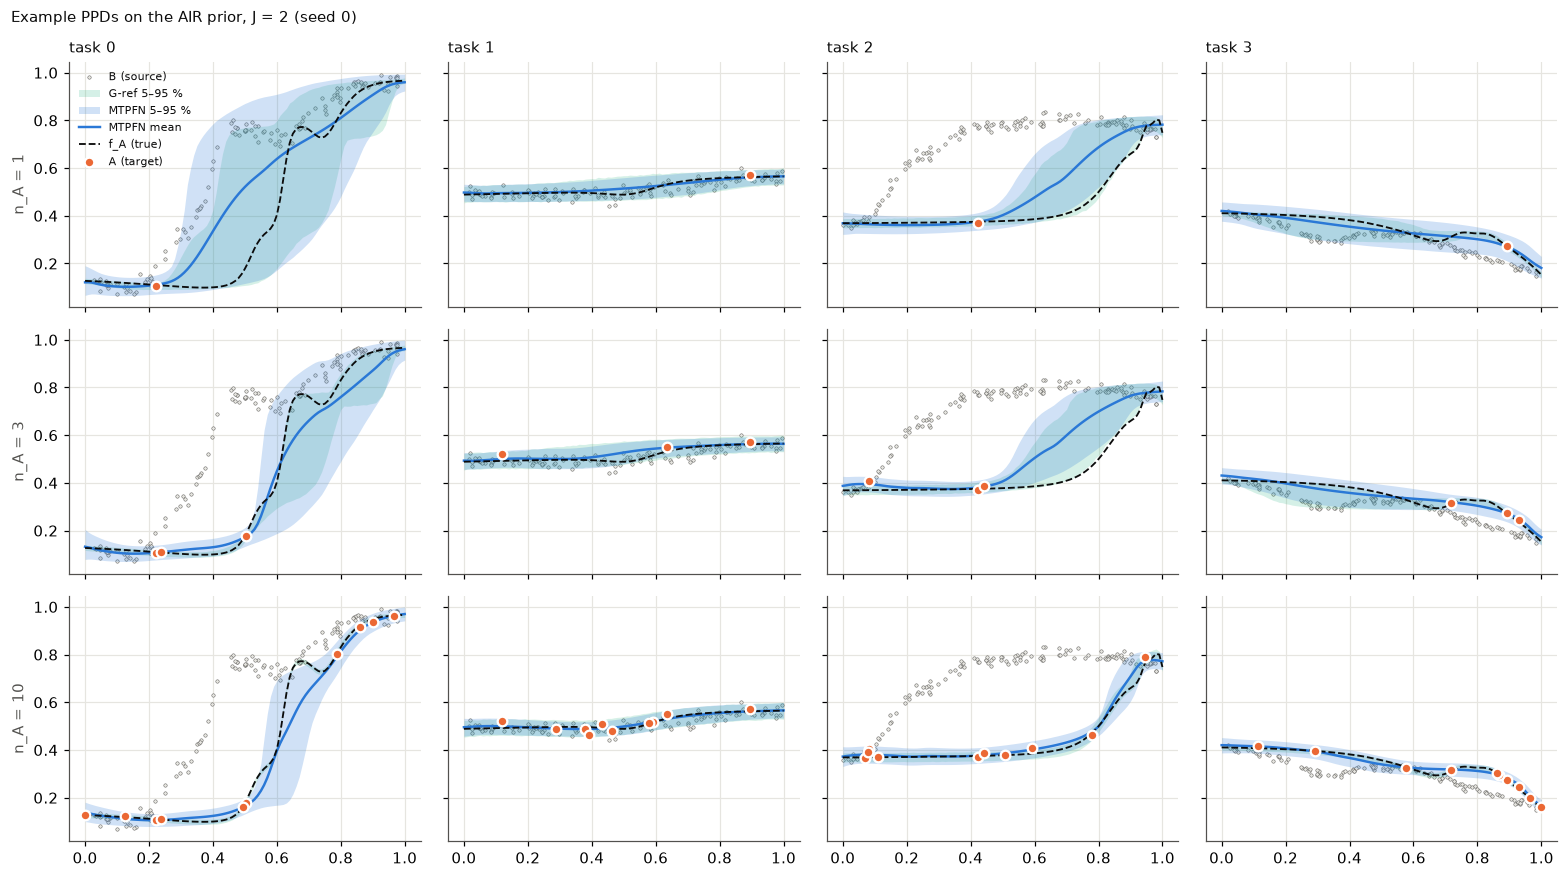

In [ ]:
e = ex[(ex.J == 2) & (ex.seed == 0)]
p = pts[(pts.J == 2) & (pts.seed == 0)]
tasks, nas = sorted(e.task.unique())[:4], sorted(e.n_a.unique())
fig, axs = plt.subplots(len(nas), len(tasks), figsize=(3.6 * len(tasks), 2.7 * len(nas)), sharex=True, sharey=True)
for r, n in enumerate(nas):
    for c, i in enumerate(tasks):
        ax = axs[r, c]
        d = e[(e.n_a == n) & (e.task == i)].pivot_table(index="x", columns="kind", values="value")
        pb = p[(p.n_a == n) & (p.task == i) & (p.set == "B")]
        pa = p[(p.n_a == n) & (p.task == i) & (p.set == "A")]
        ax.scatter(pb.x, pb.y, s=5, color=GRID, edgecolor=MUTED, lw=0.3, label="B (source)")
        if "gref_q5" in d:
            ax.fill_between(d.index, d.gref_q5, d.gref_q95, color=C[2], alpha=0.18, lw=0, label="G-ref 5–95 %")
        ax.fill_between(d.index, d.q5, d.q95, color=C[0], alpha=0.22, lw=0, label="MTPFN 5–95 %")
        ax.plot(d.index, d["mean"], color=C[0], lw=1.6, label="MTPFN mean")
        ax.plot(d.index, d.f_a, color=INK, lw=1.2, ls="--", label="f_A (true)")
        ax.scatter(pa.x, pa.y, s=40, color=C[1], edgecolor="white", lw=1.5, zorder=5, label="A (target)")
        if r == 0:
            ax.set_title(f"task {i}", loc="left", fontsize=10)
        if c == 0:
            ax.set_ylabel(f"n_A = {n}")
axs[0, 0].legend(fontsize=7, loc="upper left")
plt.suptitle("Example PPDs on the AIR prior, J = 2 (seed 0)", x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.show()

### Pre-registered reading rules

In [ ]:
r = []
s3 = s[s.n_a >= 3]
for J in sorted(s.J.unique()):
    sj = s3[s3.J == J]
    cj = ctrl[(ctrl.J == J)]
    w = cj.pivot_table(index=["seed", "n_a", "task"], columns="input", values="nll").reset_index()
    reg = (w.b - w.b_registered)[w.n_a >= 2].mean()
    use = (w.b_other - w.b).mean()
    r += [{"J": J, "rule": "MTPFN registers (conc ≥ 0.5 and |read − T| < |x* − T|)",
           "measured": f"conc {sj.conc.median():.2f}; {sj.err_read.median():.3f} vs {sj.err_id.median():.3f}",
           "holds": bool(sj.conc.median() >= 0.5 and sj.err_read.median() < sj.err_id.median())},
          {"J": J, "rule": "reads globally (conc < 0.2 and read ≈ 0.5 for most x*)",
           "measured": f"conc {sj.conc.median():.2f}; share near 0.5 {sj.read_mid.mean():.2f}",
           "holds": bool(sj.conc.median() < 0.2 and sj.read_mid.mean() > 0.5)},
          {"J": J, "rule": "the warp is its bottleneck (b − b_registered ≥ 0.1, n_A ≥ 2)",
           "measured": f"{reg:+.3f}", "holds": bool(reg >= 0.1)},
          {"J": J, "rule": "uses B (b_other − b ≥ 0.1)", "measured": f"{use:+.3f}", "holds": bool(use >= 0.1)}]
display(pd.DataFrame(r))

,J,rule,measured,holds
0,2,MTPFN registers (conc ≥ 0.5 and |read − T| < |...,conc 0.19; 0.128 vs 0.072,False
1,2,reads globally (conc < 0.2 and read ≈ 0.5 for ...,conc 0.19; share near 0.5 0.32,False
2,2,the warp is its bottleneck (b − b_registered ≥...,+0.043,False
3,2,uses B (b_other − b ≥ 0.1),+3.440,True
4,16,MTPFN registers (conc ≥ 0.5 and |read − T| < |...,conc 0.18; 0.138 vs 0.092,False
5,16,reads globally (conc < 0.2 and read ≈ 0.5 for ...,conc 0.18; share near 0.5 0.32,False
6,16,the warp is its bottleneck (b − b_registered ≥...,+0.038,False
7,16,uses B (b_other − b ≥ 0.1),+3.566,True


## Interpretation (seed 0 only, interim, 2026-11-03)

Snapshots: diagnostics `results/mtpfn/pilot_20261103-160920` (seed 0), training `results/mtpfn/pilot_20261103-132611`
(member 0 DONE, members 1–2 still running/missing). One seed only: the ± are task SEs, not seed SEs.

**Transfer (D1): large.** On pilot 3's evaluation tasks the MTPFN beats pilot 3's clean A-only PFN by
+1.12 / +0.55 / +0.23 nats per query at n_A = 1 / 3 / 10 (J = 2), and by about the same at J = 16
(+0.99 / +0.51). It clearly reads B (D3): swapping in another task's B costs +1.9 to +5.2 nats, far above the
pre-registered 0.1.

**Gap to the exact reference (D2): 0.23–0.29 nats at J = 2, roughly flat in n_A.** That is worse than pilot 2's AIR
decoder gap to G-ref (about 0.1–0.2 nats, `results/air/pilot_20261103-122813`). Pilot 3's AIR evaluation is not in
yet, so the like-for-like comparison against AIR comes with the final report.

**The warp is not its bottleneck (D3).** Giving the MTPFN a B that is already registered to A's frame (the true
T_θ⁻¹ applied to x_B) gains only 0.12 nats at n_A = 1 and nothing at n_A = 10 (rule: < 0.1 on average, does not
hold). Most of the gap stays even with a registered B: 0.11 → 0.23 nats from n_A = 1 to 10. So the MTPFN loses its
nats elsewhere than in finding the correspondence: in reading g's values out of 128 noisy B points and in the
A-side regression. Part of this is not recoverable: G-ref uses the true g, while the MTPFN sees B with noise
σ_B ≤ 0.03. A noisy-B Bayes reference (GP on B + the grid over θ) would separate the two parts and is the next
reference to add.

**It neither registers nor reads globally (D4).** The share of the sensitivity within ±0.05 of T_θ(x*) is 0.15–0.20
(rule for "registers": ≥ 0.5), and the sensitivity-weighted read location is further from T_θ(x*) (median error
0.13–0.16) than plain identity x* would be (0.07–0.09). The sensitivity maps show vertical stripes: a few B points
matter for every query x*, rather than a diagonal along T_θ. So the prediction is not a local read-out of B at T(x*).
Combined with the small warp cost this fits a model that summarises B's function (level sets, shape) and fits A
with it, without an explicit correspondence. On this prior's mostly mild warps (mean shift 0.07–0.09) that is
enough for large transfer.

**Calibration (D5): reasonable.** KS distance of the PIT from uniform 0.025–0.04.

**What it loses and why, in one line:** the MTPFN gets most of the dense-B benefit but stays 0.23–0.29 nats short of
Bayes; the shortfall is not the warp (registering B removes at most 0.12 of it) but the accuracy with which it turns
noisy B into a predictive for A.

**Open checks for the final report:** seeds 1–2; the comparison with pilot 3's AIR (decoder + q-IS) on the same tasks;
a noisy-B reference to split D2 into the irreducible part and the model's part.
